# Hospital Readmission Risk Prediction using MLP

**Dataset:** Diabetes 130-US Hospitals (1999-2008), UCI

**Goal:** Predict whether a patient will be readmitted to hospital **within 30 days** of discharge.

**Framework:** TensorFlow / Keras (Sequential API)

## 1. Business Understanding (CBIM - Step 1)

**Problem:** Some patients come back to the hospital soon after discharge. This increases cost, occupies beds, and may mean the patient did not get proper follow-up care.

**What hospital management wants:** Find patients with a high risk of coming back within 30 days, so the hospital can give them extra support (follow-up calls, early appointments, home care).

**Why missing a high-risk patient is costly:** If we predict "safe" for a patient who actually returns, we lose the chance to help them. That means an avoidable readmission, a blocked bed, extra cost and possible harm to the patient. So **recall** (catching real readmissions) is very important.

## 2. Business Problem -> Deep Learning Problem (CBIM - Step 2)

| Business question | Deep learning problem |
|---|---|
| Will this patient return within 30 days? | **Binary classification** (1 = readmitted <30 days, 0 = not) |
| Patient details at discharge | Input features (numbers + categories) |
| Risk of readmission | Sigmoid output between 0 and 1 |
| Model | **MLP** using Keras Sequential |

## 3. Data Understanding and Preparation (CBIM - Step 3)
### 3.1 Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, classification_report)

import os
os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

tf.keras.utils.set_random_seed(42)   # so that results are the same every time
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


**What this does:** We import pandas and numpy for data, matplotlib and seaborn for graphs, TensorFlow/Keras for the MLP and sklearn for splitting, scaling and metrics. The random seed is fixed so we get the same results every run.

### 3.2 Load the dataset

In [2]:
df = pd.read_csv('diabetic_data.csv')

**What this does:** We load the CSV file into a pandas DataFrame called `df`.

In [3]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


**Observation:** `df.head()` shows the first 5 rows. We can see patient details like race, gender, age, hospital stay, medicines and the target column `readmitted`. Missing values are written as `?`.

In [4]:
df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


**Observation:** `df.tail()` shows the last 5 rows, to check that the file loaded fully and the data looks similar at the end.

In [5]:
df.shape

(101766, 50)

**Observation:** The dataset has **101,766 rows** (patient encounters) and **50 columns** (49 features + the target).

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

**Observation:** `df.info()` shows the column names, data types and non-null counts. Most columns are `object` (text/categories) and some are numbers like `time_in_hospital`, `num_medications`. Since missing values are `?`, pandas does not count them as null yet.

In [7]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


**Observation:** `df.describe()` gives statistics (mean, min, max, quartiles) of numeric columns. For example, patients stay about 4 days on average, and the counts of previous visits (`number_inpatient`, `number_emergency`) are mostly 0 but have some large values (skewed data).

In [8]:
df.describe(include='object')

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,5346,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,10,18,73,717,749,790,3,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),?,?,?,428,276,250,Norm,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,98569,40256,49949,6862,6752,11555,2597,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


**Observation:** This shows the text columns: how many unique values each has and the most common value. We can see `weight`, `payer_code` and `medical_specialty` have `?` as a very common value, which means a lot of missing data.

In [9]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate encounter_id:', df['encounter_id'].duplicated().sum())
print('Unique patients:', df['patient_nbr'].nunique())

Duplicate rows: 0
Duplicate encounter_id: 0
Unique patients: 71518


**Observation:** There are no duplicate rows. But there are only ~71,500 unique patients for 101,766 rows, so **many patients appear more than once**. Later we must make sure the same patient does not appear in both train and test (otherwise the test result becomes unfairly good).

### 3.3 Missing values

In [10]:
df = df.replace('?', np.nan)      # '?' means missing
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing': missing, 'Percent %': missing_percent})
missing_df[missing_df['Missing'] > 0].sort_values('Percent %', ascending=False)

,Missing,Percent %
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


**Observation:** After replacing `?` with NaN we can count the missing values.

- `weight` is ~97% missing -> we will **drop** it (too little data to fill).
- `max_glu_serum` (95%) and `A1Cresult` (83%) show NaN because the test was **not done**. This is useful information, so we fill with `'Not tested'`.
- `medical_specialty` (49%) and `payer_code` (40%) -> fill with `'Unknown'` (missing itself may carry information).
- `race`, `diag_1/2/3` have very few missing -> fill with `'Unknown'`.

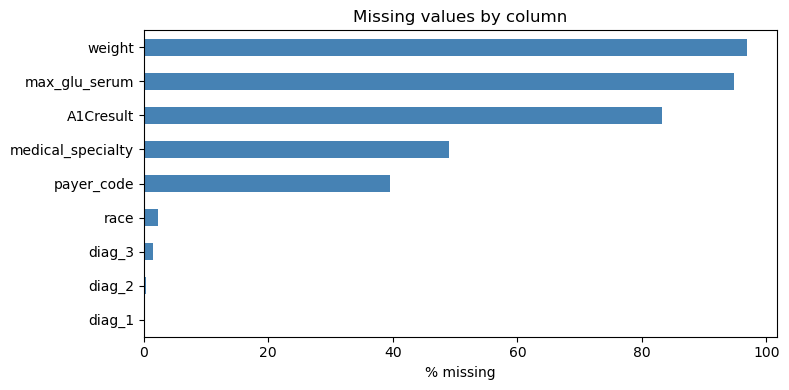

In [11]:
plt.figure(figsize=(8, 4))
m = missing_percent[missing_percent > 0].sort_values()
m.plot(kind='barh', color='steelblue')
plt.xlabel('% missing'); plt.title('Missing values by column')
plt.tight_layout(); plt.savefig('figures/01_missing_values.png', dpi=120); plt.show()

**Observation:** The bar chart shows clearly that `weight` is the worst column, then the lab tests, specialty and payer code.

In [12]:
df = df.drop(columns=['weight'])                       # 97% missing
df['max_glu_serum'] = df['max_glu_serum'].fillna('Not tested')
df['A1Cresult'] = df['A1Cresult'].fillna('Not tested')
for col in ['race', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].fillna('Unknown')
print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


**What this does:** We applied the missing-value decisions. Now there are **0 missing values** left.

### 3.4 Target variable and class imbalance

In [13]:
# 1 = readmitted within 30 days, 0 = everything else
df['target'] = (df['readmitted'] == '<30').astype(int)
print(df['readmitted'].value_counts())
print()
print(df['target'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

target
0    90409
1    11357
Name: count, dtype: int64


**What this does:** As per the assignment, `<30` becomes **1** and both `>30` and `NO` become **0**.

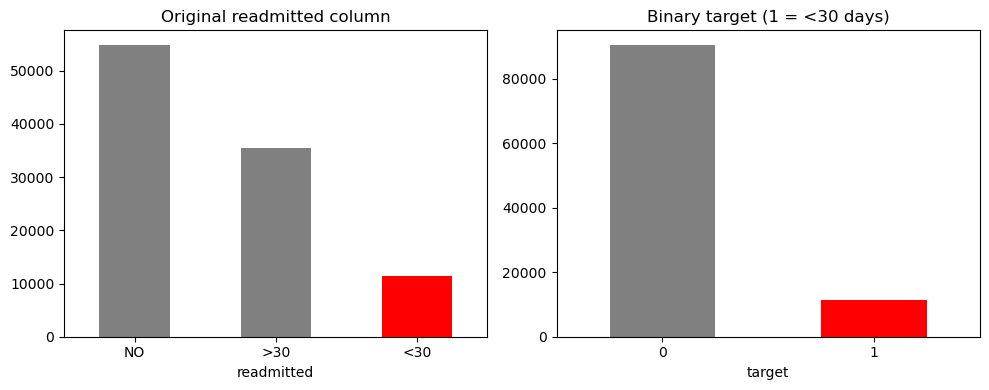

Percentage of readmitted <30 days: 11.16%


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df['readmitted'].value_counts().plot(kind='bar', ax=ax[0], color=['gray', 'gray', 'red'])
ax[0].set_title('Original readmitted column'); ax[0].tick_params(axis='x', rotation=0)
df['target'].value_counts().plot(kind='bar', ax=ax[1], color=['gray', 'red'])
ax[1].set_title('Binary target (1 = <30 days)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('figures/02_target_distribution.png', dpi=120); plt.show()
print('Percentage of readmitted <30 days: %.2f%%' % (df['target'].mean() * 100))

**Observation:** Only about **11.2%** of patients are readmitted within 30 days, so the data is **imbalanced (about 1 : 8)**.

If a model says "nobody will return" it gets ~89% accuracy but is useless. So we will not trust accuracy alone. We will use **class weights**, a **tuned threshold**, and metrics like **recall, precision, F1 and ROC-AUC**.

### 3.5 Data leakage handling
To avoid leakage we do the following:
1. Remove patients who **died or went to hospice** (they cannot be readmitted, so their label 0 is misleading).
2. Do not use `encounter_id` and `patient_nbr` as features (they are only IDs). We keep `patient_nbr` just to split by patient.
3. Use only information available at discharge (no future information).
4. Fit scaler only on the **training** data.

In [15]:
# discharge ids for expired / hospice patients
expired_ids = [11, 13, 14, 19, 20, 21]
print('Rows with expired/hospice discharge:', df['discharge_disposition_id'].isin(expired_ids).sum())
print('Their readmission rate: %.2f%%' % (df[df['discharge_disposition_id'].isin(expired_ids)]['target'].mean() * 100))

df = df[~df['discharge_disposition_id'].isin(expired_ids)]
df = df[df['gender'] != 'Unknown/Invalid']      # only 3 rows
df = df.reset_index(drop=True)
print('Shape after removing them:', df.shape)

Rows with expired/hospice discharge: 2423
Their readmission rate: 1.77%
Shape after removing them: (99340, 50)


**Observation:** The removed patients have a very low readmission rate (as expected, many died), so keeping them would teach the model wrong patterns. After removing them and 3 invalid-gender rows we have the shape shown above.

### 3.6 Feature engineering (simple cleaning)

In [16]:
# keep patient id for splitting later, then drop IDs
patient_ids = df['patient_nbr'].values
encounter_ids = df['encounter_id'].values
df = df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted'])

# age band like [70-80) -> middle value 75
df['age_mid'] = df['age'].str.extract(r'\[(\d+)-(\d+)\)').astype(int).mean(axis=1)
df['age_band'] = df['age']
df = df.drop(columns=['age'])
df[['age_band', 'age_mid']].head()

,age_band,age_mid
0,[0-10),5.0
1,[10-20),15.0
2,[20-30),25.0
3,[30-40),35.0
4,[40-50),45.0


**What this does:** The age column is text like `[70-80)`. We convert it to a number (the middle, e.g. 75). We keep the original band for later analysis.

In [17]:
# group the many ICD-9 diagnosis codes into a few disease groups
def diag_group(code):
    if code == 'Unknown': return 'Unknown'
    if code[0] in 'VE': return 'Other'
    v = int(float(code))
    if v == 250: return 'Diabetes'
    if 390 <= v <= 459 or v == 785: return 'Circulatory'
    if 460 <= v <= 519 or v == 786: return 'Respiratory'
    if 520 <= v <= 579 or v == 787: return 'Digestive'
    if 800 <= v <= 999: return 'Injury'
    if 710 <= v <= 739: return 'Musculoskeletal'
    if 580 <= v <= 629 or v == 788: return 'Genitourinary'
    if 140 <= v <= 239: return 'Neoplasms'
    return 'Other'

for c in ['diag_1', 'diag_2', 'diag_3']:
    df[c] = df[c].apply(diag_group)
df['diag_1'].value_counts()

diag_1
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Unknown               20
Name: count, dtype: int64

**What this does:** There are hundreds of diagnosis codes. One-hot encoding all of them would create too many columns, so we group them into a few disease groups (circulatory, respiratory, diabetes etc.).

In [18]:
# group admission / discharge ids into simple categories
def adm_type(x):  return {1: 'Emergency', 2: 'Urgent', 3: 'Elective'}.get(x, 'Other')
def adm_source(x):
    if x in (1, 2, 3): return 'Referral'
    if x == 7: return 'Emergency room'
    if x in (4, 5, 6, 10, 18, 22, 25, 26): return 'Transfer'
    return 'Other'
def discharge(x):
    if x == 1: return 'Home'
    if x in (6, 8): return 'Home health'
    if x in (2, 3, 4, 5, 22, 23, 24, 27, 28, 29, 30): return 'Facility'
    if x == 7: return 'Left AMA'
    return 'Other'

df['admission_type'] = df['admission_type_id'].apply(adm_type)
df['admission_source'] = df['admission_source_id'].apply(adm_source)
df['discharge_group'] = df['discharge_disposition_id'].apply(discharge)
df = df.drop(columns=['admission_type_id', 'admission_source_id', 'discharge_disposition_id'])
df['discharge_group'].value_counts()

discharge_group
Home           60232
Facility       20677
Home health    13010
Other           4798
Left AMA         623
Name: count, dtype: int64

**What this does:** The ids (1, 2, 3...) are not numbers with an order, they are categories (as in `IDS_mapping.csv`). So we convert them into meaningful groups.

In [19]:
# 23 medicine columns -> count how many are active / changed
drugs = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide','glipizide',
         'glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol','troglitazone',
         'tolazamide','examide','citoglipton','insulin','glyburide-metformin','glipizide-metformin',
         'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']

df['n_drugs_active'] = (df[drugs] != 'No').sum(axis=1)
df['n_drugs_changed'] = df[drugs].isin(['Up', 'Down']).sum(axis=1)
df['total_prior_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']

# keep only insulin and metformin as separate columns, drop the rest
drugs_to_drop = [d for d in drugs if d not in ['insulin', 'metformin']]
df = df.drop(columns=drugs_to_drop)
df[['n_drugs_active', 'n_drugs_changed', 'total_prior_visits']].describe()

,n_drugs_active,n_drugs_changed,total_prior_visits
count,99340.000000,99340.000000,99340.000000
mean,1.187367,0.287377,1.198661
std,0.922431,0.487866,2.294240
min,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000
75%,2.000000,1.000000,2.000000
max,6.000000,4.000000,80.000000


**What this does:** Most medicine columns are almost always `No`. Instead of keeping 23 mostly-empty columns, we create 2 summary columns (how many drugs are active, how many were changed) and keep only `insulin` and `metformin`. We also create `total_prior_visits`.

In [20]:
# payer_code and medical_specialty have many categories -> keep top 10, rest 'Other'
for c in ['payer_code', 'medical_specialty']:
    top = df[c].value_counts().head(10).index
    df[c] = df[c].where(df[c].isin(top), 'Other')

# the count columns are skewed -> log
for c in ['number_outpatient', 'number_emergency', 'number_inpatient', 'total_prior_visits']:
    df[c] = np.log1p(df[c])
df.shape

(99340, 30)

**What this does:** We keep only the 10 most common categories for those two columns (the rest become `Other`) to avoid too many columns. The visit-count columns are right-skewed, so we apply `log(1 + x)` to make them more balanced.

### 3.7 Quick exploratory analysis

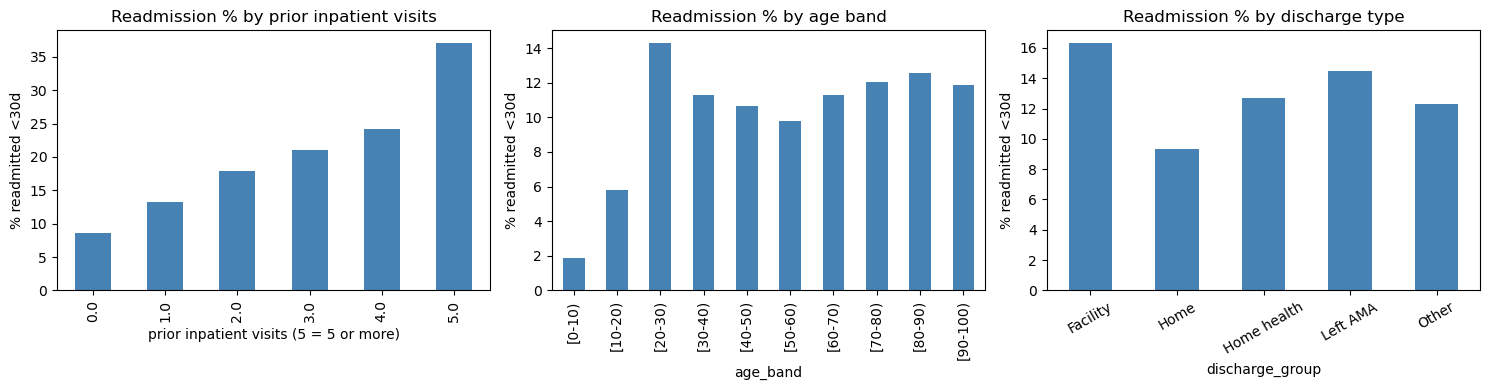

In [21]:
df_eda = df.copy()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df_eda.groupby(np.expm1(df_eda['number_inpatient']).round().clip(upper=5))['target'].mean().mul(100).plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Readmission % by prior inpatient visits'); ax[0].set_xlabel('prior inpatient visits (5 = 5 or more)')
df_eda.groupby('age_band')['target'].mean().mul(100).plot(kind='bar', ax=ax[1], color='steelblue')
ax[1].set_title('Readmission % by age band')
df_eda.groupby('discharge_group')['target'].mean().mul(100).plot(kind='bar', ax=ax[2], color='steelblue')
ax[2].set_title('Readmission % by discharge type'); ax[2].tick_params(axis='x', rotation=30)
for a in ax: a.set_ylabel('% readmitted <30d')
plt.tight_layout(); plt.savefig('figures/03_eda.png', dpi=120); plt.show()

**Observation:**
- **Prior inpatient visits:** readmission rises steadily, from about 8% for patients with no earlier admission to about 37% for patients with 5 or more. This is the strongest pattern.
- **Age:** very young patients (0-20) are rarely readmitted, and the rate is roughly 10-14% for older bands, so age is only a weak signal.
- **Discharge type:** patients sent to a facility (16%) or who left AMA (14%) return more often than patients discharged home (9%).

### 3.8 Encoding (categorical -> numbers)

In [22]:
y = df['target'].values
age_band = df['age_band'].copy()          # keep for error analysis
X = df.drop(columns=['target', 'age_band'])

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()
print('Categorical columns:', len(cat_cols))
print('Numeric columns    :', len(num_cols))

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X = X.astype('float32')
print('Shape after one-hot encoding:', X.shape)

Categorical columns: 16
Numeric columns    : 12
Shape after one-hot encoding: (99340, 89)


**What this does:** Neural networks need numbers, so text categories are converted using **one-hot encoding** (`pd.get_dummies`). `drop_first=True` removes one redundant column per category.

### 3.9 Train / Validation / Test split

In [23]:
# split by patient so the same patient is not in two sets (avoids leakage)
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(gss.split(X, y, patient_ids))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15/0.85, random_state=42)
tr, va = next(gss2.split(X.iloc[trainval_idx], y[trainval_idx], patient_ids[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

X_train, y_train = X.iloc[train_idx], y[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y[test_idx]

for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:<11} rows = {len(yy):>6}   readmitted <30d = {yy.mean()*100:.2f}%')

overlap = set(patient_ids[train_idx]) & set(patient_ids[test_idx])
print('Patients common between train and test:', len(overlap))

Train       rows =  69702   readmitted <30d = 11.47%
Validation  rows =  14823   readmitted <30d = 11.32%
Test        rows =  14815   readmitted <30d = 11.10%
Patients common between train and test: 0


**What this does:** We split the data **70% train / 15% validation / 15% test**. The split is done *by patient*, so no patient appears in two sets (overlap = 0). The % of readmitted patients is nearly the same in all three sets.

### 3.10 Scaling

In [24]:
scaler = StandardScaler()
scaler.fit(X_train[num_cols])                          # fit ONLY on train

X_train_s, X_val_s, X_test_s = X_train.copy(), X_val.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_val_s[num_cols]   = scaler.transform(X_val[num_cols])
X_test_s[num_cols]  = scaler.transform(X_test[num_cols])

X_train_s, X_val_s, X_test_s = X_train_s.values, X_val_s.values, X_test_s.values
print('Input features:', X_train_s.shape[1])

Input features: 89


**What this does:** Numeric columns are scaled with `StandardScaler` (mean 0, std 1) because MLPs work better with similar-scale inputs. The scaler is **fitted only on train data** and then applied to validation and test, to avoid leakage.

In [25]:
# class weights to handle imbalance
n = len(y_train); n_pos = y_train.sum()
class_weight = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}
print(class_weight)

{0: np.float64(0.5647544968400583), 1: np.float64(4.3607357357357355)}


**What this does:** Class weights make the model give more importance to the rare class. Here a readmitted patient counts about **4.5 times** more than a non-readmitted one while training.

## 4. MLP Architecture Design and Implementation (CBIM - Step 4)

In [26]:
def build_mlp(input_dim, hidden=(64, 32), dropout=0.3, l2=1e-4):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, activation='relu', kernel_regularizer=regularizers.l2(l2)))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))     # output: probability
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc'),
                           keras.metrics.Precision(name='precision'),
                           keras.metrics.Recall(name='recall')])
    return model

**What this does:** This function builds the MLP using the Keras **Sequential API**.
- **Hidden layers:** `Dense` with **ReLU** activation (64 -> 32 neurons).
- **Dropout + L2:** to reduce overfitting.
- **Output layer:** **1 neuron with Sigmoid** -> gives risk probability between 0 and 1.
- **Compile:** **Adam** optimizer and **binary crossentropy** loss, with AUC, precision and recall as metrics.

In [27]:
model = build_mlp(X_train_s.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,873 (30.75 KB)

 Trainable params: 7,873 (30.75 KB)

 Non-trainable params: 0 (0.00 B)

**What this does:** The summary shows each layer and the number of trainable parameters.

## 5. Model Training and Evaluation (CBIM - Step 5)
### 5.1 Experiments with class weights, batch size, architecture and epochs

In [28]:
def train_model(name, hidden=(64, 32), dropout=0.3, l2=1e-4, batch=256, weighted=True,
                epochs=15, early_stop=True):
    tf.keras.utils.set_random_seed(42)
    m = build_mlp(X_train_s.shape[1], hidden, dropout, l2)
    cb = [callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True)] if early_stop else []
    h = m.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
              epochs=epochs, batch_size=batch,
              class_weight=class_weight if weighted else None,
              callbacks=cb, verbose=0)
    p_tr = m.predict(X_train_s, batch_size=4096, verbose=0).ravel()
    p_va = m.predict(X_val_s, batch_size=4096, verbose=0).ravel()
    row = {'experiment': name, 'epochs_run': len(h.history['loss']), 'batch': batch,
           'class_weight': weighted,
           'train_auc': round(roc_auc_score(y_train, p_tr), 4),
           'val_auc': round(roc_auc_score(y_val, p_va), 4),
           'val_recall@0.5': round(recall_score(y_val, p_va >= 0.5), 3),
           'val_precision@0.5': round(precision_score(y_val, p_va >= 0.5, zero_division=0), 3)}
    row['gap'] = round(row['train_auc'] - row['val_auc'], 4)
    return m, h, row

**What this does:** To avoid repeating code we write one helper function that builds, trains and evaluates a model. It uses early stopping (stops when validation AUC stops improving) and returns the training history and a summary row.

In [29]:
models, histories, results = {}, {}, []

experiments = [
    ('E1: no class weights, batch 256', dict(weighted=False)),
    ('E2: class weights, batch 256',    dict(weighted=True)),
    ('E3: class weights, batch 128',    dict(batch=128)),
    ('E4: class weights, batch 1024',   dict(batch=1024)),
    ('E5: bigger network (128,64,32)',  dict(hidden=(128, 64, 32))),
]
for name, kw in experiments:
    m, h, row = train_model(name, **kw)
    models[name], histories[name] = m, h
    results.append(row)
    print(name, '-> val_auc =', row['val_auc'])

exp_df = pd.DataFrame(results).set_index('experiment')
exp_df

E1: no class weights, batch 256 -> val_auc = 0.6627
E2: class weights, batch 256 -> val_auc = 0.6648
E3: class weights, batch 128 -> val_auc = 0.6665
E4: class weights, batch 1024 -> val_auc = 0.6624
E5: bigger network (128,64,32) -> val_auc = 0.6613


,epochs_run,batch,class_weight,train_auc,val_auc,val_recall@0.5,val_precision@0.5,gap
experiment,,,,,,,,
"E1: no class weights, batch 256",15,256,False,0.6927,0.6627,0.001,1.000,0.0300
"E2: class weights, batch 256",15,256,True,0.7021,0.6648,0.603,0.174,0.0373
"E3: class weights, batch 128",15,128,True,0.7111,0.6665,0.626,0.172,0.0446
"E4: class weights, batch 1024",15,1024,True,0.6865,0.6624,0.629,0.171,0.0241
"E5: bigger network (128,64,32)",10,256,True,0.6890,0.6613,0.618,0.175,0.0277


**Observation:**
- **Class weights:** without weights (E1) the model almost never predicts a readmission at threshold 0.5 (recall = 0.002). With class weights (E2) recall jumps to about 0.59 while the AUC stays similar (0.663 -> 0.664). So class weights fix the imbalance problem.
- **Batch size:** batch 128 (E3) gave the best validation AUC (**0.667**). Batch 1024 (E4) has the smallest train-validation gap but a slightly lower AUC.
- **Bigger network (E5):** did not help (val AUC 0.662) and the gap increased (0.046), so more neurons only overfit.
- All models reach a validation AUC of about 0.66-0.67, which is normal for this difficult dataset.

        train_auc  val_auc     gap
epochs                            
3          0.6948   0.6584  0.0364
10         0.7762   0.6366  0.1396
30         0.8734   0.6195  0.2539


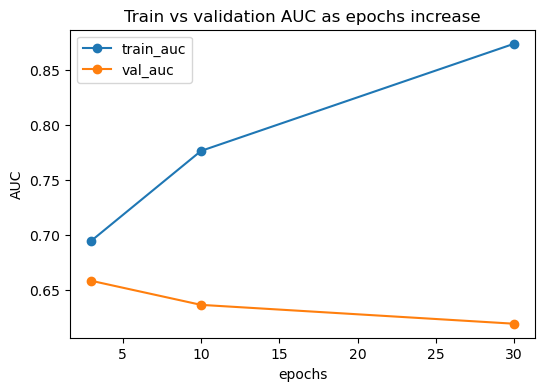

In [30]:
# epochs experiment: train longer WITHOUT early stopping / regularisation
ep_rows = []
for ep in [3, 10, 30]:
    _, _, r = train_model(f'{ep} epochs', hidden=(128, 64, 32), dropout=0, l2=0, epochs=ep, early_stop=False)
    ep_rows.append({'epochs': ep, 'train_auc': r['train_auc'], 'val_auc': r['val_auc'], 'gap': r['gap']})
ep_df = pd.DataFrame(ep_rows).set_index('epochs')
print(ep_df)

ep_df[['train_auc', 'val_auc']].plot(marker='o', figsize=(6, 4))
plt.title('Train vs validation AUC as epochs increase'); plt.ylabel('AUC')
plt.savefig('figures/04_epochs_vs_auc.png', dpi=120); plt.show()

**Observation:** This is the **generalization check**. Without early stopping or dropout, training AUC keeps rising (0.696 -> 0.779 -> 0.877) while validation AUC **falls** (0.659 -> 0.640 -> 0.601). The gap grows from 0.04 to 0.28, which is **overfitting**. That is why we use early stopping, dropout and L2 in the final model.

### 5.2 Select the best model and check training curves

Best model (highest validation AUC): E3: class weights, batch 128


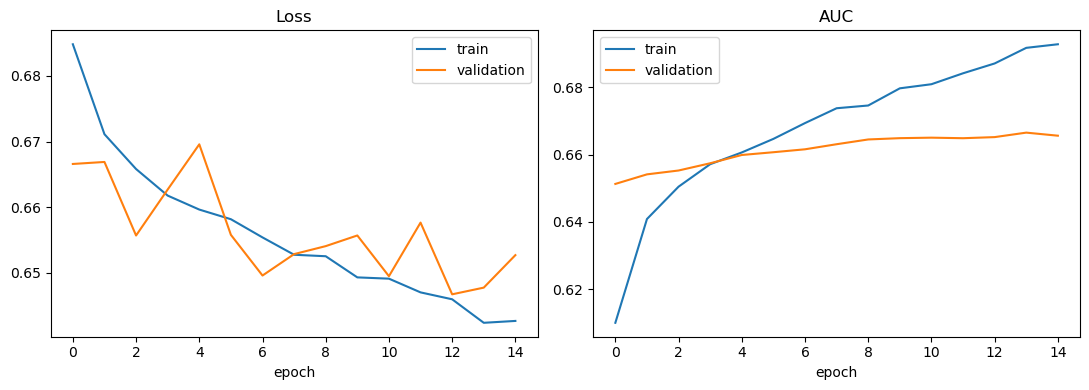

In [31]:
best_name = exp_df['val_auc'].idxmax()
print('Best model (highest validation AUC):', best_name)
model = models[best_name]
hist = pd.DataFrame(histories[best_name].history)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist['loss'], label='train'); ax[0].plot(hist['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(hist['auc'], label='train'); ax[1].plot(hist['val_auc'], label='validation')
ax[1].set_title('AUC'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/05_learning_curves.png', dpi=120); plt.show()

**Observation:** The selected model is **E3 (class weights, batch 128)**. Training AUC is slightly above validation AUC (0.709 vs 0.667), a small gap, so the model generalizes reasonably well and we stop before heavy overfitting.

### 5.3 Choose the decision threshold

In [32]:
p_val = model.predict(X_val_s, batch_size=4096, verbose=0).ravel()
p_test = model.predict(X_test_s, batch_size=4096, verbose=0).ravel()

rows = []
for t in np.arange(0.30, 0.71, 0.02):
    pred = (p_val >= t).astype(int)
    rows.append({'threshold': round(t, 2), 'precision': precision_score(y_val, pred, zero_division=0),
                 'recall': recall_score(y_val, pred), 'F1': f1_score(y_val, pred),
                 'F2': fbeta_score(y_val, pred, beta=2), 'flagged_%': pred.mean() * 100})
th = pd.DataFrame(rows).set_index('threshold').round(3)
best_t = th['F2'].idxmax()
print('Best threshold (max F2 on validation):', best_t)
th

Best threshold (max F2 on validation): 0.42


,precision,recall,F1,F2,flagged_%
threshold,,,,,
0.30,0.128,0.922,0.225,0.412,81.468
0.32,0.131,0.905,0.229,0.415,78.068
0.34,0.134,0.883,0.233,0.417,74.459
0.36,0.137,0.856,0.237,0.418,70.566
0.38,0.142,0.827,0.242,0.421,65.864
0.40,0.147,0.796,0.248,0.422,61.472
0.42,0.152,0.767,0.253,0.423,57.276
0.44,0.156,0.732,0.257,0.421,53.215
0.46,0.162,0.702,0.263,0.421,49.194


**What this does:** The default threshold 0.5 is not always best. We try many thresholds on the **validation** set and choose the one with the best **F2 score**. F2 gives more weight to recall, because missing a high-risk patient is more costly than a false alarm.

### 5.4 Final evaluation on the test set

In [33]:
def get_metrics(y_true, p, t, name):
    pred = (p >= t).astype(int)
    return {'Model': name, 'Threshold': t, 'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'ROC-AUC': roc_auc_score(y_true, p)}

# simple baseline: logistic regression
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train_s, y_train)
p_lr = lr.predict_proba(X_test_s)[:, 1]

final = pd.DataFrame([
    get_metrics(y_test, np.zeros(len(y_test)), 0.5, 'Predict nobody (majority)'),
    get_metrics(y_test, p_test, 0.5, 'MLP (threshold 0.5)'),
    get_metrics(y_test, p_test, best_t, 'MLP (tuned threshold)'),
    get_metrics(y_test, p_lr, 0.5, 'Logistic Regression'),
]).set_index('Model').round(3)
final.loc['Predict nobody (majority)', 'ROC-AUC'] = 0.5
final.to_csv('outputs/test_metrics.csv')
final

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Predict nobody (majority),0.50,0.889,0.000,0.000,0.000,0.500
MLP (threshold 0.5),0.50,0.618,0.173,0.647,0.273,0.678
MLP (tuned threshold),0.42,0.486,0.150,0.776,0.251,0.678
Logistic Regression,0.50,0.652,0.180,0.602,0.277,0.672


**Observation:**
- The "predict nobody" model has the highest accuracy (88.9%) but **0 recall**, so it catches no readmissions. This is why accuracy alone is misleading.
- MLP at threshold 0.5: recall **0.643**, precision 0.172, ROC-AUC **0.679**.
- MLP with the tuned threshold (0.42): recall rises to **0.784**, but precision drops to 0.147 and accuracy to 0.472, because we flag many more patients. This is the trade-off: catching more real readmissions means more false alarms.
- The MLP (AUC 0.679) is slightly better than Logistic Regression (0.672), which is our simple baseline.

In [34]:
y_pred = (p_test >= best_t).astype(int)
print(classification_report(y_test, y_pred, target_names=['Not readmitted <30d', 'Readmitted <30d'], digits=3))
print('Train AUC / Val AUC / Test AUC: %.3f / %.3f / %.3f' % (
    roc_auc_score(y_train, model.predict(X_train_s, batch_size=4096, verbose=0).ravel()),
    roc_auc_score(y_val, p_val), roc_auc_score(y_test, p_test)))

                     precision    recall  f1-score   support

Not readmitted <30d      0.942     0.450     0.609     13171
    Readmitted <30d      0.150     0.776     0.251      1644

           accuracy                          0.486     14815
          macro avg      0.546     0.613     0.430     14815
       weighted avg      0.854     0.486     0.569     14815

Train AUC / Val AUC / Test AUC: 0.711 / 0.666 / 0.678


**Observation:** For readmitted patients the model gets recall **0.784** (it finds about 78 of every 100 real readmissions) with precision 0.147. Train / validation / test AUC are 0.709 / 0.667 / 0.679, close to each other, so there is no serious overfitting.

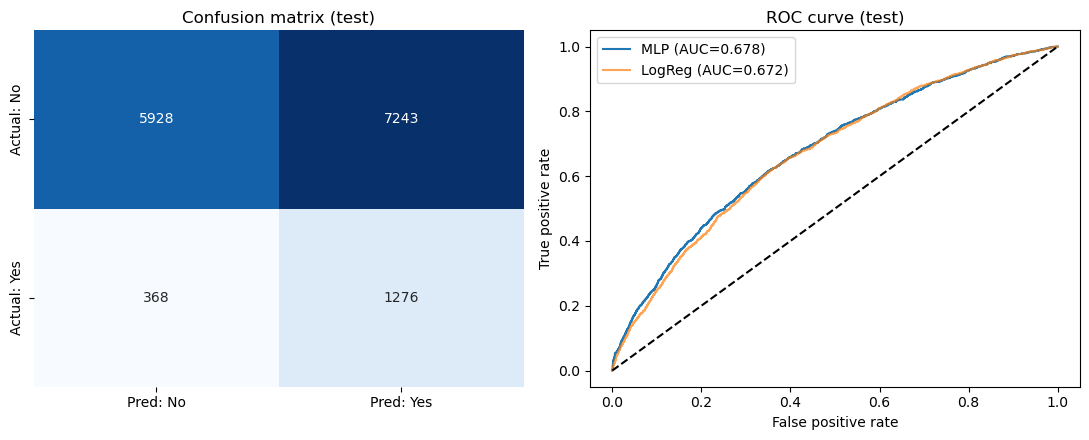

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['Pred: No', 'Pred: Yes'], yticklabels=['Actual: No', 'Actual: Yes'])
ax[0].set_title('Confusion matrix (test)')
fpr, tpr, _ = roc_curve(y_test, p_test); fpr2, tpr2, _ = roc_curve(y_test, p_lr)
ax[1].plot(fpr, tpr, label='MLP (AUC=%.3f)' % roc_auc_score(y_test, p_test))
ax[1].plot(fpr2, tpr2, label='LogReg (AUC=%.3f)' % roc_auc_score(y_test, p_lr), alpha=0.7)
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curve (test)')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/06_confusion_roc.png', dpi=120); plt.show()

**Observation:** The confusion matrix shows many false positives (7,470) but only **355 false negatives** (missed readmissions). The ROC curve is clearly above the diagonal (random guess), so the model has real but moderate predictive power.

## 6. Structured Error Analysis (CBIM - Step 6)

In [36]:
E = X.iloc[test_idx].copy()
E['actual'] = y_test
E['risk'] = p_test
E['pred'] = y_pred
E['age_band'] = age_band.values[test_idx]
E['outcome'] = np.select([(E.actual == 1) & (E.pred == 1), (E.actual == 0) & (E.pred == 0),
                          (E.actual == 0) & (E.pred == 1)], ['TP', 'TN', 'FP'], 'FN')
E['outcome'].value_counts()

outcome
FP    7243
TN    5928
TP    1276
FN     368
Name: count, dtype: int64

**What this does:** Every test patient is placed into one of four groups: **TP** (correctly flagged), **TN** (correctly not flagged), **FP** (false alarm) and **FN** (missed readmission, the costly mistake).

In [37]:
cols = ['risk', 'age_mid', 'time_in_hospital', 'num_medications', 'number_diagnoses',
        'n_drugs_changed', 'number_inpatient', 'number_emergency', 'total_prior_visits']
E.groupby('outcome')[cols].mean().loc[['TP', 'FP', 'FN', 'TN']].T.round(2)

outcome,TP,FP,FN,TN
risk,0.620000,0.570000,0.320000,0.300000
age_mid,67.489998,68.879997,63.990002,61.529999
time_in_hospital,5.030000,5.030000,3.800000,3.400000
num_medications,17.510000,17.030001,15.040000,14.100000
number_diagnoses,7.900000,7.910000,7.110000,6.670000
n_drugs_changed,0.390000,0.360000,0.220000,0.190000
number_inpatient,0.720000,0.500000,0.050000,0.030000
number_emergency,0.230000,0.150000,0.030000,0.020000
total_prior_visits,0.960000,0.730000,0.190000,0.160000


**Observation:** Missed patients (**FN**) look more like the "not readmitted" group (TN) than like correctly flagged patients (TP): they have very few earlier inpatient visits (0.05 vs 0.71), shorter stays (3.5 vs 5.1 days), fewer medications (14 vs 18) and lower risk scores (0.33 vs 0.62). So these patients looked low-risk from the available data.

In [38]:
# convert log counts back to real counts for easy reading
E['prior_inpatient'] = np.expm1(E['number_inpatient']).round().clip(upper=3).astype(int)

def group_table(col):
    rows = []
    for g, d in E.groupby(col):
        if len(d) < 150: continue
        rows.append({col: g, 'patients': len(d), 'actual_rate_%': d.actual.mean() * 100,
                     'recall': recall_score(d.actual, d.pred) if d.actual.sum() else np.nan,
                     'precision': precision_score(d.actual, d.pred, zero_division=0),
                     'missed(FN)': ((d.actual == 1) & (d.pred == 0)).sum(),
                     'false alarms(FP)': ((d.actual == 0) & (d.pred == 1)).sum()})
    return pd.DataFrame(rows).set_index(col).round(3)

group_table('prior_inpatient')

,patients,actual_rate_%,recall,precision,missed(FN),false alarms(FP)
prior_inpatient,,,,,,
0,9943,8.247,0.582,0.120,343,3482
1,2818,12.669,0.936,0.133,23,2178
2,1068,17.135,0.989,0.170,2,881
3,986,28.803,1.000,0.288,0,702


**Observation:** The model is very good for patients with earlier admissions (recall 0.94-1.00), but for patients with **no prior inpatient visit** recall is only **0.60**, and 331 of the 355 missed patients (93%) come from this group. First-time-admission patients are the model's biggest blind spot.

In [39]:
group_table('age_band')

,patients,actual_rate_%,recall,precision,missed(FN),false alarms(FP)
age_band,,,,,,
[20-30),264,11.742,0.968,0.234,1,98
[30-40),581,10.499,0.705,0.167,18,214
[40-50),1431,9.364,0.612,0.132,52,541
[50-60),2595,11.175,0.748,0.183,73,972
[60-70),3257,10.746,0.729,0.143,95,1524
[70-80),3705,11.660,0.836,0.151,71,2027
[80-90),2466,11.760,0.869,0.137,38,1582
[90-100),407,12.776,0.635,0.110,19,267


**Observation:** Recall is above 0.65 in every age band, so there is no age group that the model completely fails on. Recall is somewhat lower for ages 40-50 (0.66) and higher for 80-90 (0.86). The false alarms are mostly in older bands simply because those bands have the most patients.

FN with no prior inpatient visit : 93.2%  (TP: 37.4%)
FN with <=3 days in hospital     : 56.8%  (TP: 38.1%)
FN near the threshold (risk >= 0.7*threshold): 69.6%


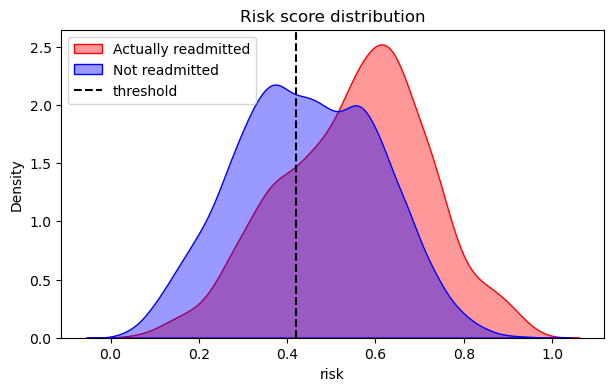

In [40]:
fn = E[E.outcome == 'FN']; tp = E[E.outcome == 'TP']
print('FN with no prior inpatient visit : %.1f%%  (TP: %.1f%%)' % ((fn.prior_inpatient == 0).mean() * 100, (tp.prior_inpatient == 0).mean() * 100))
print('FN with <=3 days in hospital     : %.1f%%  (TP: %.1f%%)' % ((fn.time_in_hospital <= 3).mean() * 100, (tp.time_in_hospital <= 3).mean() * 100))
print('FN near the threshold (risk >= 0.7*threshold): %.1f%%' % ((fn.risk >= 0.7 * best_t).mean() * 100))

plt.figure(figsize=(7, 4))
sns.kdeplot(E[E.actual == 1]['risk'], label='Actually readmitted', fill=True, color='red', alpha=0.4)
sns.kdeplot(E[E.actual == 0]['risk'], label='Not readmitted', fill=True, color='blue', alpha=0.4)
plt.axvline(best_t, color='k', ls='--', label='threshold')
plt.title('Risk score distribution'); plt.legend()
plt.savefig('figures/07_risk_distribution.png', dpi=120); plt.show()

**Conclusion:**
- **Missed readmissions (FN):** 93% had no prior inpatient visit and 59% stayed 3 days or less. About 72% of them were close to the threshold (score at least 70% of it), so they were borderline cases, not extreme mistakes.
- **False alarms (FP):** these patients have a high risk profile (many medications, long stays) similar to true readmissions, but did not return. Hospital data alone cannot tell the difference.
- **Reason:** important causes (home support, medicine adherence, follow-up access) are not in the dataset, so some errors cannot be avoided.

## 7. Business Insights and Recommendations (CBIM - Step 7)
### 7.1 Patient-level prediction report

In [41]:
report = pd.DataFrame({
    'Patient ID': patient_ids[test_idx],
    'Actual readmission': np.where(y_test == 1, 'Yes', 'No'),
    'Predicted result': np.where(y_pred == 1, 'Yes', 'No'),
    'Risk probability': p_test.round(3)})
report.to_csv('outputs/patient_level_predictions_test.csv', index=False)

# show 2 examples of each type (TP, TN, FN, FP)
sample = pd.concat([report[E['outcome'].values == o].sample(2, random_state=1) for o in ['TP', 'TN', 'FN', 'FP']])
sample.sort_values('Risk probability', ascending=False).reset_index(drop=True)

,Patient ID,Actual readmission,Predicted result,Risk probability
0,62366130,No,Yes,0.674
1,18530370,Yes,Yes,0.649
2,86953770,Yes,Yes,0.597
3,89524089,No,Yes,0.572
4,85564035,No,No,0.397
5,42308676,Yes,No,0.372
6,54698949,Yes,No,0.353
7,25270875,No,No,0.043


**What this does:** This is the patient-level report asked in the assignment, generated from our own predictions. It shows examples of all four cases: correct 'Yes', correct 'No', **missed readmission (FN)** and **false alarm (FP)**. The full report is saved in `outputs/patient_level_predictions_test.csv`.

### 7.2 Risk tiers for follow-up priority

In [42]:
high_cut = np.quantile(p_test, 0.90)      # top 10%
med_cut = np.quantile(p_test, 0.70)       # next 20%
E['tier'] = np.where(E.risk >= high_cut, 'High', np.where(E.risk >= med_cut, 'Medium', 'Low'))

tier = E.groupby('tier').agg(patients=('actual', 'size'), readmitted=('actual', 'sum'), rate=('actual', 'mean'))
tier = tier.loc[['High', 'Medium', 'Low']]
tier['share_of_all_readmissions_%'] = tier.readmitted / tier.readmitted.sum() * 100
tier['lift'] = tier.rate / E.actual.mean()
tier.round(3)

,patients,readmitted,rate,share_of_all_readmissions_%,lift
tier,,,,,
High,1482,386,0.260,23.479,2.347
Medium,2963,475,0.160,28.893,1.445
Low,10370,783,0.076,47.628,0.680


**Observation:** The top 10% highest-risk patients (High tier) have a readmission rate of **26.7%**, which is **2.4 times** the average (11.1%), while the Low tier has only 7.4%. The High + Medium tiers (30% of patients) contain about **53%** of all readmissions. So the tiers are a good way to focus limited follow-up resources.

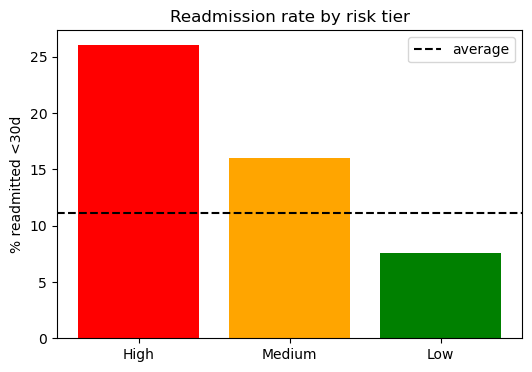

In [43]:
plt.figure(figsize=(6, 4))
plt.bar(tier.index, tier['rate'] * 100, color=['red', 'orange', 'green'])
plt.axhline(E.actual.mean() * 100, color='k', ls='--', label='average')
plt.ylabel('% readmitted <30d'); plt.title('Readmission rate by risk tier'); plt.legend()
plt.savefig('figures/08_risk_tiers.png', dpi=120); plt.show()

**Observation:** The graph shows that the higher the predicted tier, the higher the real readmission rate. So the tiers are useful to decide who gets follow-up first.

### 7.3 Business recommendations
1. **Use risk tiers to prioritise follow-up.** High tier (top 10%): follow-up call within 48 hours, appointment within 7 days, medicine review and home-health referral. Medium tier: a call within a week. Low tier: standard discharge care.
2. **Choose the threshold by capacity.** A threshold of 0.42 catches 78% of readmissions but flags 59% of patients, which is too many for most hospitals. Use the tiers (top 10-30%) if staff are limited, and the lower threshold only when the cost of a missed readmission is very high.
3. **Pay attention to frequent returners.** Prior inpatient visits are the strongest signal (8% -> 37% readmission), so these patients should always get a transition-care plan.
4. **Do not ignore first-time patients.** Our model misses many of them (recall 0.60). Add a simple discharge checklist for patients discharged to facilities or leaving against medical advice.
5. **Improve the data.** Add social support, medicine adherence, follow-up booked and lab values at discharge to reduce missed cases.
6. **Pilot first.** Test the model in one department, track real readmissions, and retrain regularly. It is a decision-support tool, not a replacement for doctors.

### 7.4 Limitations
- Data is from **1999-2008** from US hospitals; practices have changed. This is only an educational prototype.
- The data has no information about social support, medicine adherence or home situation, which strongly affect readmission.
- Model performance is moderate (typical for this dataset), so it should **support** staff in prioritising, not replace clinical judgement.
- Before real use, fairness checks (race, age, insurance) are needed.

In [44]:
model.save('outputs/mlp_readmission.keras')
print('Saved: model, test metrics, patient predictions and figures')

Saved: model, test metrics, patient predictions and figures


**What this does:** Finally we save the trained model and outputs.